In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, auc
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
DATA_PATH = "kolkata_weather_jan_june_2026.csv"  # letakkan CSV di folder yang sama


In [2]:
from pathlib import Path

if not Path(DATA_PATH).exists():
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = next(iter(uploaded.keys()))

df = pd.read_csv(DATA_PATH)
print("Ukuran dataset:", df.shape)
display(df.head())


Ukuran dataset: (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [3]:
print("Informasi dataset:")
df.info()

print("\\nJumlah baris dan kolom:", df.shape)
print("\\nTipe data:")
display(df.dtypes.rename("dtype").to_frame())

print("\\nStatistik deskriptif:")
display(df.describe(include="all").T)


Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   str    
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   str    
 12  sunset                       1827 non-null   str    
 13  sunshine_d

,dtype
time,str
weather_code,int64
temperature_2m_mean,float64
temperature_2m_max,float64
temperature_2m_min,float64
precipitation_sum,float64
rain_sum,float64
precipitation_hours,float64
wind_speed_10m_max,float64
wind_gusts_10m_max,float64


\nStatistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
time,1827,1827,2021-06-30,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_code,1827.0,NaN,NaN,NaN,34.143952,28.997216,0.0,3.0,51.0,63.0,65.0
temperature_2m_mean,1827.0,NaN,NaN,NaN,26.26486,4.05022,15.0,23.4,27.4,29.1,35.2
temperature_2m_max,1827.0,NaN,NaN,NaN,31.099234,3.924558,19.6,28.7,31.3,33.3,43.9
temperature_2m_min,1827.0,NaN,NaN,NaN,22.477066,4.847343,10.2,18.6,24.6,26.2,30.6
precipitation_sum,1827.0,NaN,NaN,NaN,5.429119,9.550693,0.0,0.0,0.4,7.35,80.5
rain_sum,1827.0,NaN,NaN,NaN,5.429119,9.550693,0.0,0.0,0.4,7.35,80.5
precipitation_hours,1827.0,NaN,NaN,NaN,4.952928,6.275264,0.0,0.0,2.0,9.0,24.0
wind_speed_10m_max,1827.0,NaN,NaN,NaN,13.782157,5.106847,4.5,10.0,12.6,16.6,44.0
wind_gusts_10m_max,1827.0,NaN,NaN,NaN,30.756596,9.081119,11.5,24.1,29.5,36.0,83.9


In [4]:
# Pemeriksaan kualitas data
print("Jumlah missing value per kolom:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

print("Jumlah duplikasi:", df.duplicated().sum())
print("\\nDistribusi target weather_code:")
display(df["weather_code"].value_counts().sort_index().to_frame("jumlah"))


Jumlah missing value per kolom:


,missing_values
time,0
weather_code,0
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
rain_sum,0
precipitation_hours,0
wind_speed_10m_max,0
wind_gusts_10m_max,0


Jumlah duplikasi: 0
\nDistribusi target weather_code:


,jumlah
weather_code,
0,228
1,94
2,78
3,406
51,167
53,108
55,40
61,145
63,419


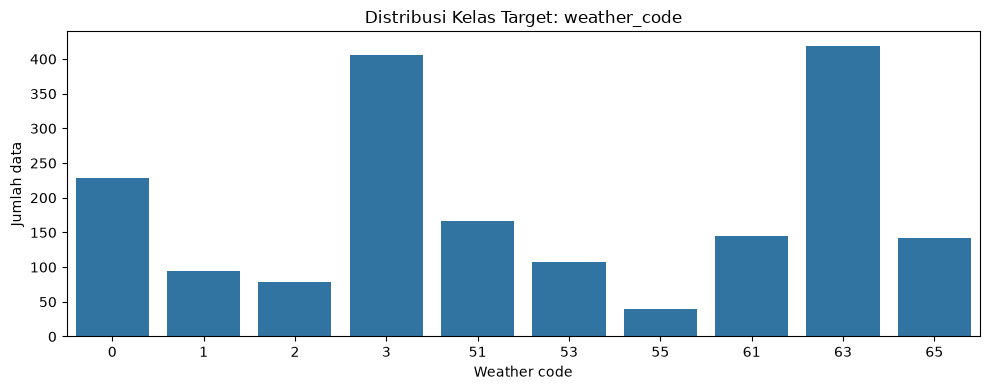

In [5]:
# EDA: distribusi target
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="weather_code", order=sorted(df["weather_code"].dropna().unique()))
plt.title("Distribusi Kelas Target: weather_code")
plt.xlabel("Weather code")
plt.ylabel("Jumlah data")
plt.tight_layout()
plt.show()


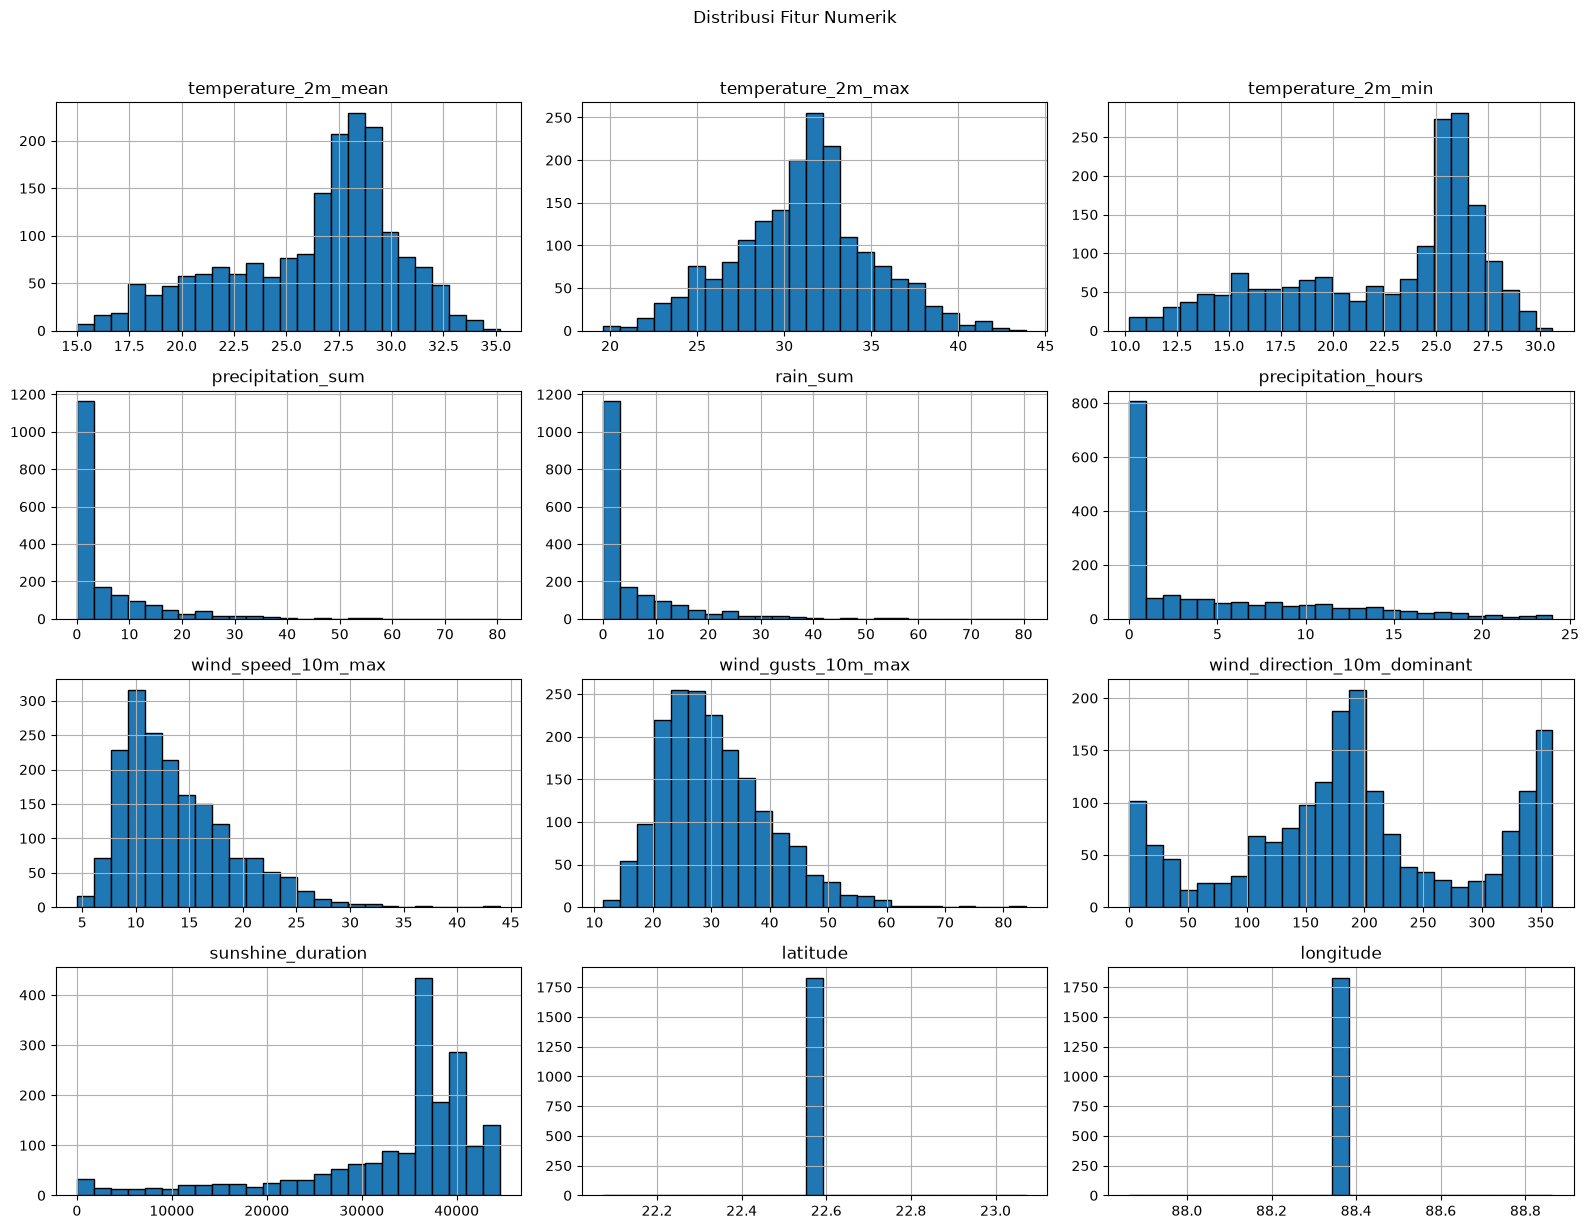

In [6]:
# EDA: histogram fitur numerik
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_features_for_eda = [c for c in numeric_cols if c != "weather_code"]

df[numeric_features_for_eda].hist(figsize=(16, 12), bins=25, edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()


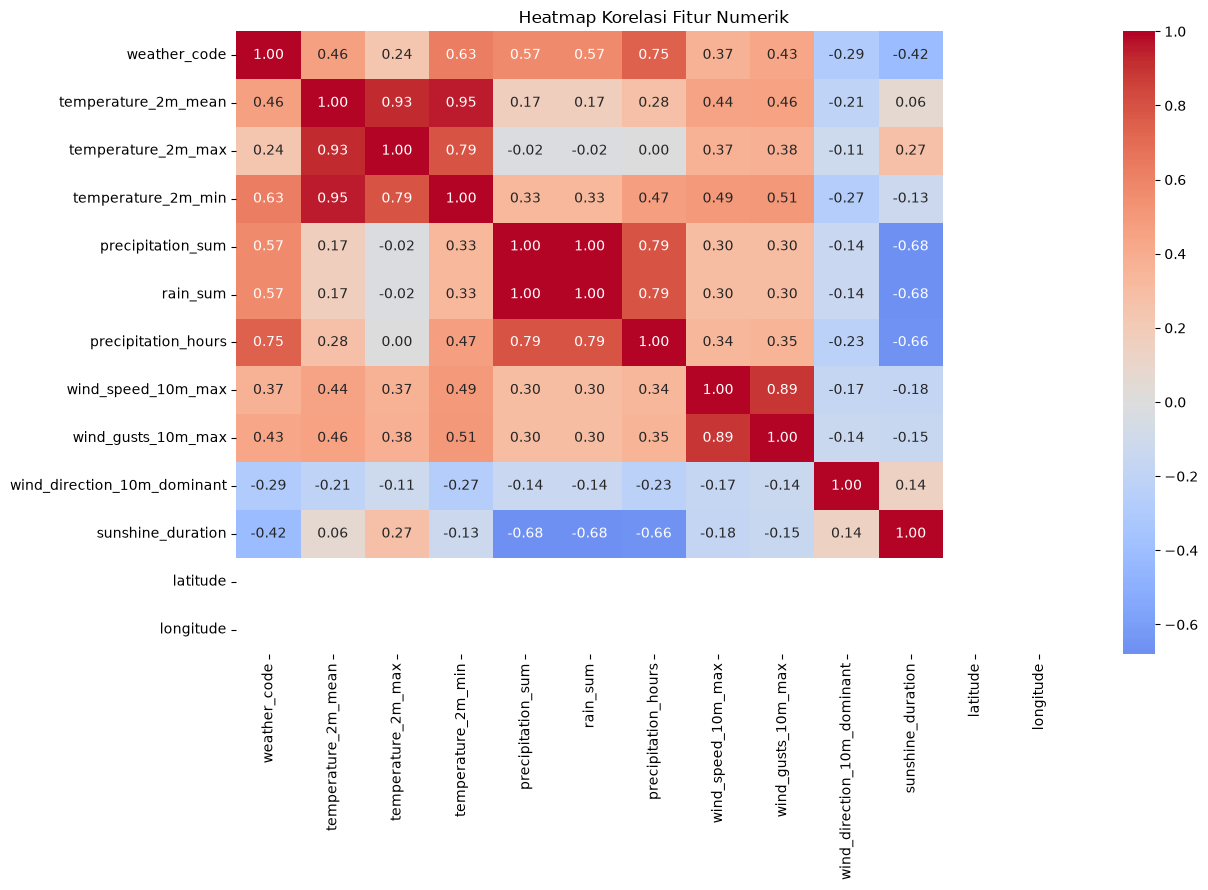

In [7]:
# Heatmap korelasi numerik. weather_code ditampilkan untuk eksplorasi saja.
plt.figure(figsize=(13, 9))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()


In [8]:
# Feature engineering tanggal.
# sunrise, sunset, city, latitude, longitude tidak dipakai sebagai fitur model karena
# identitas lokasi konstan dan waktu matahari berkorelasi kuat dengan tanggal/lokasi.
data = df.copy()
data["time"] = pd.to_datetime(data["time"], errors="coerce")
data["month"] = data["time"].dt.month
data["day_of_year"] = data["time"].dt.dayofyear
data["day_of_week"] = data["time"].dt.dayofweek

TARGET = "weather_code"
excluded = [TARGET, "time", "sunrise", "sunset", "city", "latitude", "longitude"]
feature_cols = [
    c for c in data.columns
    if c not in excluded and pd.api.types.is_numeric_dtype(data[c])
]
X = data[feature_cols].copy()
y_raw = data[TARGET].copy()

# Buang baris jika target/tanggal tidak valid, lalu samakan indeks.
valid = y_raw.notna() & data["time"].notna()
X = X.loc[valid].reset_index(drop=True)
y_raw = y_raw.loc[valid].reset_index(drop=True)

print("Fitur yang digunakan:", feature_cols)
print("Jumlah sampel:", len(X))
print("Jumlah kelas target:", y_raw.nunique())


Fitur yang digunakan: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration', 'month', 'day_of_year', 'day_of_week']
Jumlah sampel: 1827
Jumlah kelas target: 10


In [10]:
# Split dilakukan sebelum fitting imputer/scaler agar preprocessing tidak bocor ke data uji.
# LabelEncoder hanya mengubah label target menjadi indeks integer untuk kompatibilitas XGBoost.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw.astype(str))
class_names = label_encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Kelas:", list(class_names))


Data latih: (1461, 13) | Data uji: (366, 13)
Kelas: ['0', '1', '2', '3', '51', '53', '55', '61', '63', '65']


In [11]:
# Model XGBoost Classifier
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    objective="multi:softprob",
    num_class=len(class_names),
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
model.fit(X_train_imp, y_train)

y_pred = model.predict(X_test_imp)
y_proba = model.predict_proba(X_test_imp)
print("Model selesai dilatih.")


Model selesai dilatih.


In [12]:
# Evaluasi metrik klasifikasi multi-kelas
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
}
try:
    metrics["ROC-AUC (OvR macro)"] = roc_auc_score(
        y_test, y_proba, multi_class="ovr", average="macro"
    )
except ValueError:
    metrics["ROC-AUC (OvR macro)"] = np.nan

display(pd.DataFrame({"Metrik": list(metrics.keys()), "Nilai": list(metrics.values())}))
print(classification_report(
    y_test, y_pred, labels=np.arange(len(class_names)),
    target_names=class_names, zero_division=0
))


,Metrik,Nilai
0,Accuracy,0.628415
1,Precision (macro),0.555569
2,Recall (macro),0.490112
3,F1-score (macro),0.488853
4,ROC-AUC (OvR macro),0.933958


              precision    recall  f1-score   support

           0       0.52      0.70      0.60        46
           1       0.25      0.05      0.09        19
           2       0.50      0.06      0.11        16
           3       0.61      0.72      0.66        81
          51       0.93      0.85      0.89        33
          53       0.63      0.77      0.69        22
          55       0.33      0.12      0.18         8
          61       0.48      0.41      0.44        29
          63       0.68      0.82      0.75        84
          65       0.61      0.39      0.48        28

    accuracy                           0.63       366
   macro avg       0.56      0.49      0.49       366
weighted avg       0.61      0.63      0.60       366



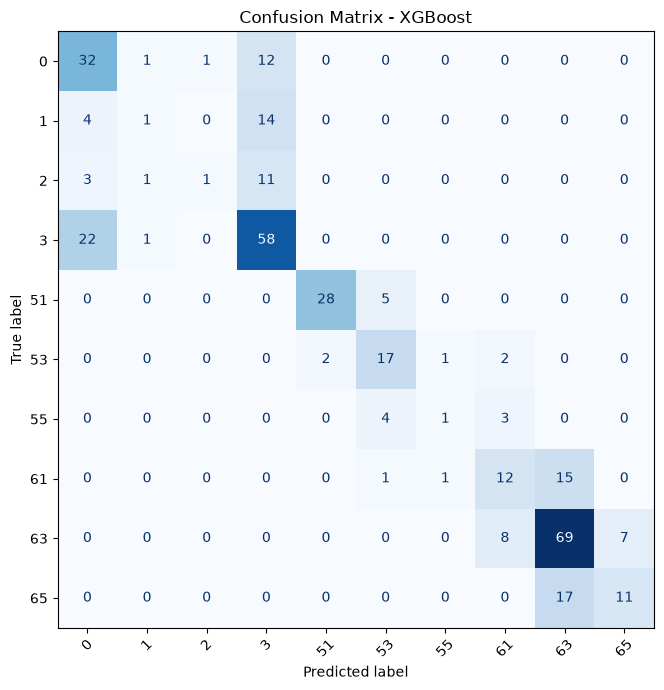

In [13]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix - XGBoost")
plt.tight_layout()
plt.show()


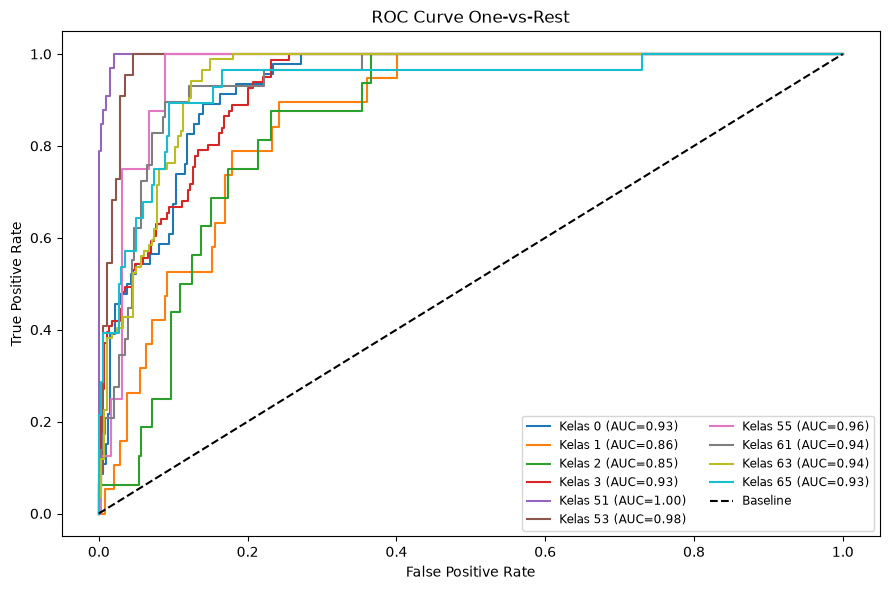

In [14]:
# ROC curve multi-kelas dengan pendekatan One-vs-Rest
y_test_bin = label_binarize(y_test, classes=np.arange(len(class_names)))
plt.figure(figsize=(9, 6))
valid_roc = 0
for i, class_name in enumerate(class_names):
    if i < y_test_bin.shape[1] and len(np.unique(y_test_bin[:, i])) == 2:
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"Kelas {class_name} (AUC={roc_auc:.2f})")
        valid_roc += 1
plt.plot([0, 1], [0, 1], "k--", label="Baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve One-vs-Rest")
if valid_roc:
    plt.legend(loc="lower right", fontsize="small", ncol=2)
plt.tight_layout()
plt.show()


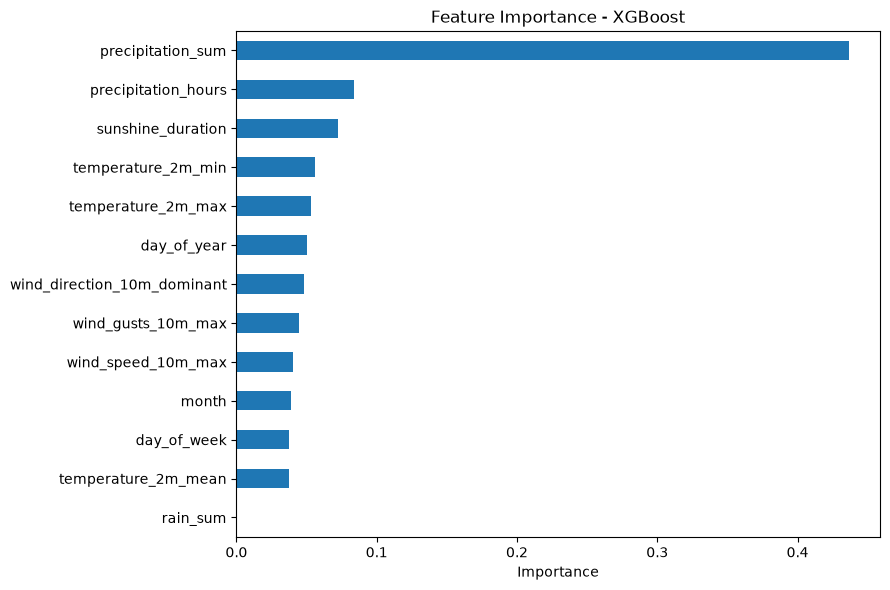

,importance
precipitation_sum,0.436918
precipitation_hours,0.083902
sunshine_duration,0.072598
temperature_2m_min,0.055953
temperature_2m_max,0.053346
day_of_year,0.050172
wind_direction_10m_dominant,0.048112
wind_gusts_10m_max,0.044484
wind_speed_10m_max,0.040193
month,0.038875


In [15]:
# Feature importance
importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
plt.figure(figsize=(9, 6))
importance.plot(kind="barh")
plt.title("Feature Importance - XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame("importance"))


In [18]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# 1. Buat salinan DataFrame
export_df = X.copy()

# 2. Ubah tipe data feature_cols menjadi float agar dapat menampung nilai desimal hasil normalisasi
export_df[feature_cols] = export_df[feature_cols].astype(float)

# 3. Fit dan transform dengan MinMaxScaler
export_scaler = MinMaxScaler()
export_df[feature_cols] = export_scaler.fit_transform(export_df[feature_cols])

# 4. Tambahkan kolom target dan ekspor ke file CSV
export_df[TARGET] = y_raw.astype(str).values
export_path = "kolkata_weather_jan_june_2026.csv"
export_df.to_csv(export_path, index=False)

print(f"Data fitur yang dinormalisasi disimpan ke: {export_path}")
display(export_df.head())

Data fitur yang dinormalisasi disimpan ke: kolkata_weather_jan_june_2026.csv


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,month,day_of_year,day_of_week,weather_code
0,0.737624,0.567901,0.872549,0.144099,0.144099,0.250000,0.486076,0.477901,0.572222,0.467536,0.454545,0.493151,0.333333,65
1,0.732673,0.567901,0.862745,0.130435,0.130435,0.416667,0.369620,0.353591,0.536111,0.481032,0.545455,0.495890,0.500000,63
2,0.702970,0.518519,0.862745,0.197516,0.197516,0.541667,0.359494,0.308011,0.580556,0.275785,0.545455,0.498630,0.666667,63
3,0.702970,0.547325,0.838235,0.094410,0.094410,0.458333,0.278481,0.283149,0.561111,0.661591,0.545455,0.501370,0.833333,63
4,0.673267,0.514403,0.818627,0.099379,0.099379,0.458333,0.189873,0.248619,0.500000,0.923180,0.545455,0.504110,1.000000,63


In [19]:
# Simpan artefak model agar dapat digunakan kembali.
# File pickle dibuat lokal di folder kerja notebook.
import pickle

with open("xgboost_weather_artifacts.pkl", "wb") as f:
    pickle.dump({
        "model": model,
        "imputer": imputer,
        "label_encoder": label_encoder,
        "feature_cols": feature_cols,
        "class_names": list(class_names)
    }, f)

print("Artefak model disimpan: xgboost_weather_artifacts.pkl")


Artefak model disimpan: xgboost_weather_artifacts.pkl
